# Student Dropout & Academic Success - Model Experimentation
## Data understanding and preprocessing
Run from the `notebooks/` folder. Raw data must be at `../data/students_raw.csv`.

In [ ]:
import sys; sys.path.append("../src")
import numpy as np, pandas as pd, sklearn
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from preprocessing import *

print("scikit-learn version:", sklearn.__version__)
df = load_raw("../data/students_raw.csv")
print("Shape:", df.shape)
display(df.head())
print(df.dtypes.value_counts())
print("Missing values:", df.isna().sum().sum())
print("Duplicate rows:", df.duplicated().sum())
print(df["Nacionality"].value_counts(normalize=True).head(3).round(3))

scikit-learn version: 1.9.1
Shape: (4424, 37)


,Marital status,Application mode,Application order,Course,Daytime/evening attendance,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,Father's qualification,...,Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target
0,1,17,5,171,1,1,122.0,1,19,12,...,0,0,0,0,0.000000,0,10.8,1.4,1.74,Dropout
1,1,15,1,9254,1,1,160.0,1,1,3,...,0,6,6,6,13.666667,0,13.9,-0.3,0.79,Graduate
2,1,1,5,9070,1,1,122.0,1,37,37,...,0,6,0,0,0.000000,0,10.8,1.4,1.74,Dropout
3,1,17,2,9773,1,1,122.0,1,38,37,...,0,6,10,5,12.400000,0,9.4,-0.8,-3.12,Graduate
4,2,39,1,8014,0,1,100.0,1,37,38,...,0,6,6,6,13.000000,0,13.9,-0.3,0.79,Graduate


int64      29
float64     7
object      1
Name: count, dtype: int64
Missing values: 0
Duplicate rows: 0
Nacionality
1     0.975
41    0.009
26    0.003
Name: proportion, dtype: float64


### Target distribution

Target
Graduate    2209
Dropout     1421
Enrolled     794
Name: count, dtype: int64
Target
Graduate    49.93
Dropout     32.12
Enrolled    17.95
Name: count, dtype: float64


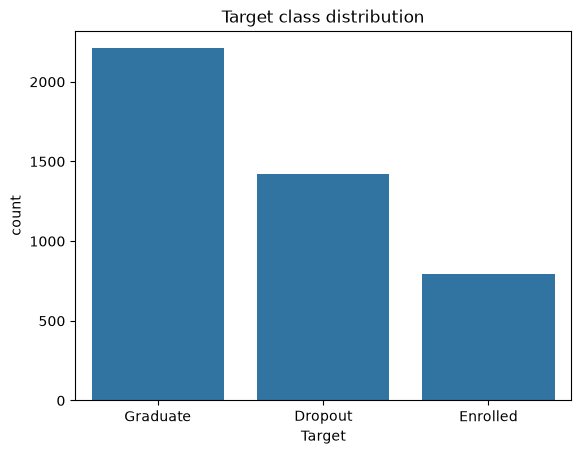

In [ ]:
counts = df[TARGET_COL].value_counts()
print(counts); print((counts / len(df) * 100).round(2))
sns.countplot(data=df, x=TARGET_COL, order=counts.index)
plt.title("Target class distribution"); plt.show()

### Column groups and outlier check (outliers are flagged, not removed)

19 numeric | 9 nominal | 8 binary
Age at enrollment: 441 IQR outliers
Admission grade: 86 IQR outliers
Previous qualification (grade): 179 IQR outliers
Curricular units 1st sem (grade): 726 IQR outliers


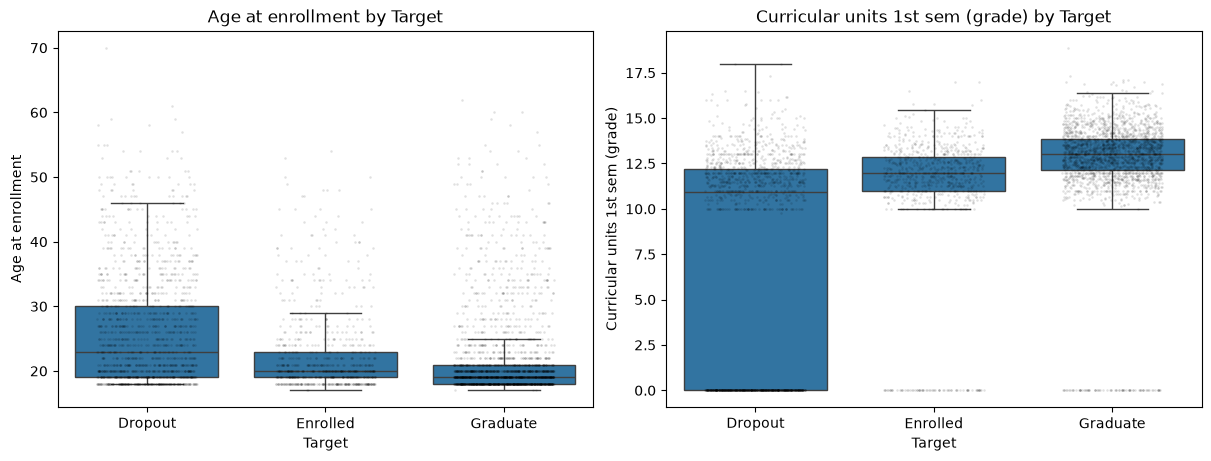

Grade == 0 rows: 718 {'Dropout': 570, 'Graduate': 77, 'Enrolled': 71}
Share with grade == 0 per class: {'Dropout': 0.401, 'Enrolled': 0.089, 'Graduate': 0.035}


In [ ]:
numeric_cols = get_numeric_cols(df)
print(len(numeric_cols), "numeric |", len(NOMINAL_COLS), "nominal |", len(BINARY_COLS), "binary")

for c in ["Age at enrollment", "Admission grade",
          "Previous qualification (grade)", "Curricular units 1st sem (grade)"]:
    q1, q3 = df[c].quantile([.25, .75]); iqr = q3 - q1
    n_out = ((df[c] < q1 - 1.5*iqr) | (df[c] > q3 + 1.5*iqr)).sum()
    print(f"{c}: {n_out} IQR outliers")

class_order = ["Dropout", "Enrolled", "Graduate"]   # same order as the label encoding
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), constrained_layout=True)
for ax, col in zip(axes, ["Age at enrollment", "Curricular units 1st sem (grade)"]):
    # box = quartiles and whiskers; individual points are drawn separately so overlapping values stay visible
    sns.boxplot(data=df, x=TARGET_COL, y=col, order=class_order, ax=ax, showfliers=False)
    sns.stripplot(data=df, x=TARGET_COL, y=col, order=class_order, ax=ax,
                  color="black", size=1.8, alpha=0.12, jitter=0.28)
    ax.set_title(f"{col} by Target")
    ax.set_xlabel("Target")
    ax.set_ylabel(col)
plt.show()

# Rows whose 1st-semester grade is exactly 0
g = "Curricular units 1st sem (grade)"
print("Grade == 0 rows:", (df[g] == 0).sum(), df.loc[df[g] == 0, TARGET_COL].value_counts().to_dict())
print("Share with grade == 0 per class:", df.groupby(TARGET_COL)[g].apply(lambda s: (s == 0).mean()).round(3).to_dict())

### Stratified split, fit on training only, leakage check, save the split

In [ ]:
X = df.drop(columns=TARGET_COL); y = df[TARGET_COL]
label_enc = LabelEncoder().fit(y)
print(dict(zip(label_enc.classes_, label_enc.transform(label_enc.classes_))))

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE)
print(X_train.shape, X_test.shape)
print(y_train.value_counts(normalize=True).round(4).to_dict())
print(y_test.value_counts(normalize=True).round(4).to_dict())

prep = build_preprocessor(numeric_cols, scale=True)
Xt_train = prep.fit_transform(X_train)   # fit on TRAIN only
Xt_test = prep.transform(X_test)         # transform only
print("Processed shapes:", Xt_train.shape, Xt_test.shape, "| NaNs:", np.isnan(Xt_train).sum())

scaler = prep.named_transformers_["numeric"].named_steps["scale"]
i = numeric_cols.index("Age at enrollment")
print("scaler mean:", round(scaler.mean_[i], 4),
      "| train mean:", round(X_train["Age at enrollment"].mean(), 4),
      "| full-data mean:", round(X["Age at enrollment"].mean(), 4))

X_train.assign(Target=y_train).to_csv("../data/train_raw.csv", index=False)
X_test.assign(Target=y_test).to_csv("../test_data.csv", index=False)
print("Saved ../data/train_raw.csv and ../test_data.csv")

{'Dropout': np.int64(0), 'Enrolled': np.int64(1), 'Graduate': np.int64(2)}
(3539, 36) (885, 36)
{'Graduate': 0.4993, 'Dropout': 0.3213, 'Enrolled': 0.1794}
{'Graduate': 0.4994, 'Dropout': 0.3209, 'Enrolled': 0.1797}
Processed shapes: (3539, 106) (885, 106) | NaNs: 0
scaler mean: 23.2628 | train mean: 23.2628 | full-data mean: 23.2651
Saved ../data/train_raw.csv and ../test_data.csv


## Train the five classifiers
Each model is a full Pipeline (preprocessing + classifier). Hyper-parameters are chosen with 5-fold stratified cross-validation on the **training split only** (scoring = macro-F1).

In [ ]:
from train_models import train_all, save_all, MODEL_FILES, PREPROCESSOR_FILES
from evaluate_models import evaluate_all

y_train_enc = label_enc.transform(y_train)
y_test_enc = label_enc.transform(y_test)

fitted_models, cv_table = train_all(X_train, y_train_enc, numeric_cols)
pd.set_option("display.max_colwidth", 80)
display(cv_table)

/opt/miniconda3/lib/python3.13/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/opt/miniconda3/lib/python3.13/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/opt/miniconda3/lib/python3.13/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/opt/miniconda3/lib/python3.13/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.

,ML Model,Best CV macro-F1,Best parameters
0,Logistic Regression,0.7067,{'C': 1}
1,Decision Tree,0.6687,"{'max_depth': 6, 'min_samples_leaf': 10}"
2,KNN,0.6207,"{'n_neighbors': 5, 'weights': 'distance'}"
3,Naive Bayes,0.6246,{'var_smoothing': 0.1}
4,SVM,0.7038,"{'C': 10, 'gamma': 0.01}"


## Evaluate on the held-out test split (six metrics)

,ML Model,Accuracy,AUC,Precision,Recall,F1,MCC
0,Logistic Regression,0.7785,0.8879,0.7366,0.6993,0.7112,0.6328
1,Decision Tree,0.7446,0.8490,0.6962,0.6534,0.6641,0.5744
2,KNN,0.7096,0.8025,0.6639,0.6146,0.6263,0.5152
3,Naive Bayes,0.7040,0.8197,0.6633,0.6365,0.6438,0.5128
4,SVM,0.7819,0.8887,0.7456,0.7016,0.7154,0.6387


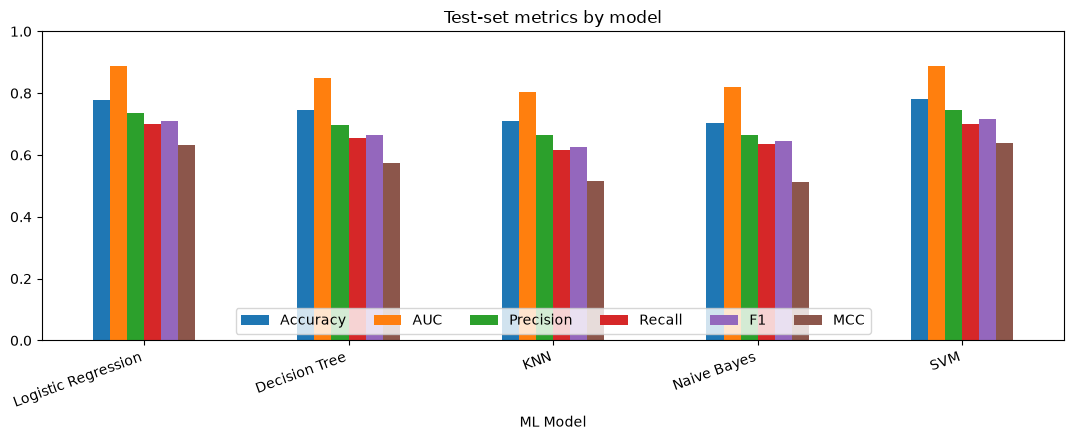

In [ ]:
results_df, test_preds = evaluate_all(fitted_models, X_test, y_test_enc)
display(results_df)
results_df.to_csv("../results/model_comparison.csv", index=False)

results_df.set_index("ML Model").plot(kind="bar", figsize=(11, 4.5), ylim=(0, 1))
plt.title("Test-set metrics by model"); plt.xticks(rotation=20, ha="right")
plt.legend(ncol=6, loc="lower center"); plt.tight_layout(); plt.show()

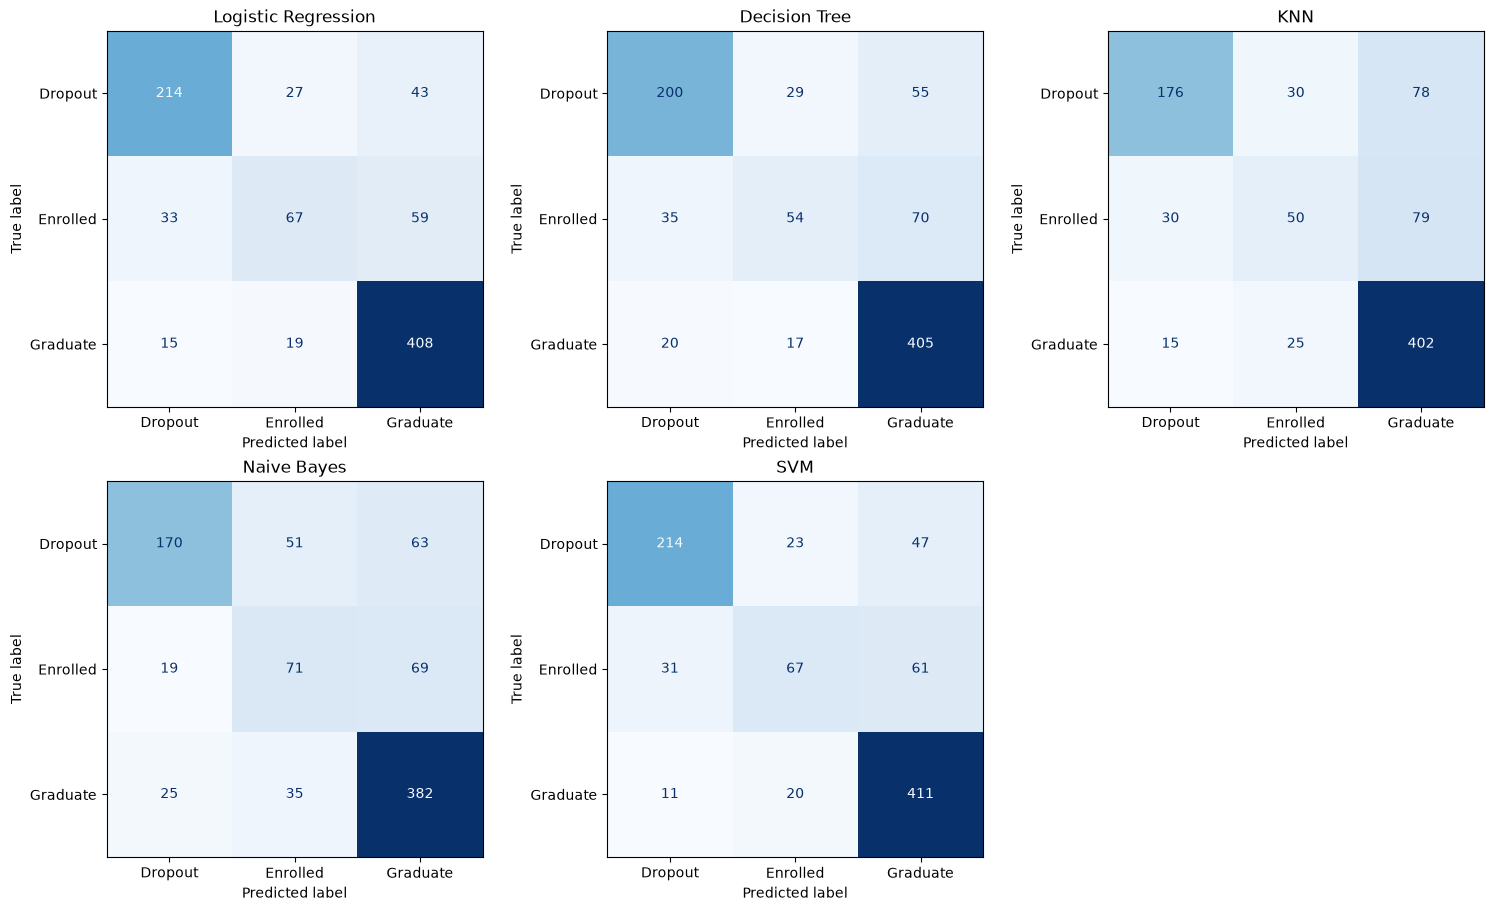

Logistic Regression
              precision    recall  f1-score   support

     Dropout      0.817     0.754     0.784       284
    Enrolled      0.593     0.421     0.493       159
    Graduate      0.800     0.923     0.857       442

    accuracy                          0.779       885
   macro avg      0.737     0.699     0.711       885
weighted avg      0.768     0.779     0.768       885

Decision Tree
              precision    recall  f1-score   support

     Dropout      0.784     0.704     0.742       284
    Enrolled      0.540     0.340     0.417       159
    Graduate      0.764     0.916     0.833       442

    accuracy                          0.745       885
   macro avg      0.696     0.653     0.664       885
weighted avg      0.730     0.745     0.729       885

KNN
              precision    recall  f1-score   support

     Dropout      0.796     0.620     0.697       284
    Enrolled      0.476     0.314     0.379       159
    Graduate      0.719     0.910    

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report

fig, axes = plt.subplots(2, 3, figsize=(15, 9), constrained_layout=True)
for ax, (name, pred) in zip(axes.ravel(), test_preds.items()):
    ConfusionMatrixDisplay(confusion_matrix(y_test_enc, pred),
                           display_labels=label_enc.classes_).plot(ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(name)
axes.ravel()[-1].axis("off")
fig.savefig("../results/confusion_matrices.png", dpi=150)
plt.show()

for name, pred in test_preds.items():
    print("=" * 60); print(name)
    print(classification_report(y_test_enc, pred, target_names=label_enc.classes_, digits=3))

## Save the fitted pipelines and verify they reload

In [ ]:
import joblib
from sklearn.pipeline import Pipeline
meta = save_all(fitted_models, label_enc, numeric_cols, X.columns, model_dir="../model")

reloaded = {
    name: Pipeline([
        ("prep", joblib.load("../model/" + PREPROCESSOR_FILES[name])),
        ("clf", joblib.load("../model/" + MODEL_FILES[name])),
    ])
    for name in MODEL_FILES
}
same = {name: bool((reloaded[name].predict(X_test) == fitted_models[name].predict(X_test)).all())
        for name in reloaded}
print("Reloaded models give identical predictions:", same)
print("Saved with scikit-learn", meta["sklearn_version"], "- use this version in requirements.txt")

Reloaded models give identical predictions: {'Logistic Regression': True, 'Decision Tree': True, 'KNN': True, 'Naive Bayes': True, 'SVM': True}
Saved with scikit-learn 1.9.1 - use this version in requirements.txt
